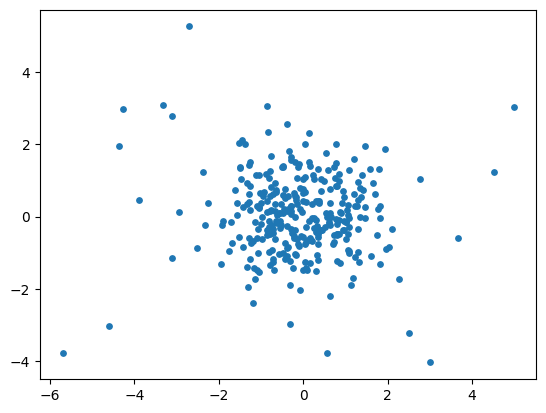

In [50]:
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
normal = rng.normal(0, 1, (300, 2))  # 평균:0, 표준편차:1 로 (300,2) 크기로 데이터 생성
outlier = rng.uniform(-6, 6, (15, 2))    
X = np.vstack([normal, outlier]) # 정상과 이상 값을 합한다.

plt.scatter(X[:, 0], X[:, 1], s=15)
plt.show()

In [ ]:
# StandardScaler() 로 표준화
# OneClassSVM() 으로 학습 진행
# nu = 0.05 : 경계선 밖으로 허용할 비율의 상한(0~1) 0에 가까울수록 경계선과 점 사이가 빡빡해짐
# gamma: 클수록 영향력이 짧아져서 결정 경계가 구불구불해지고 예민해짐
oc = make_pipeline(StandardScaler(), OneClassSVM(kernel='rbf', nu=0.05, gamma=0.5)).fit(normal)

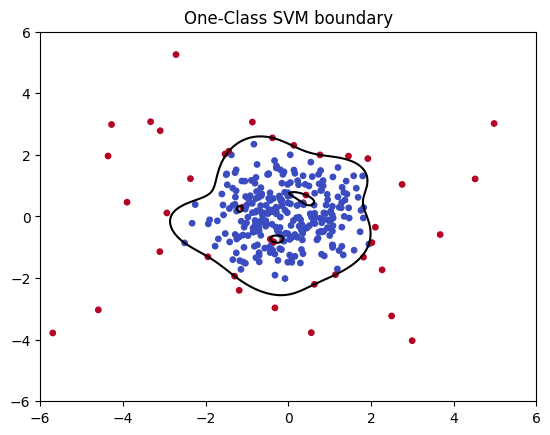

In [58]:
# -6 ~ 6 까지 200개로 쪼갠 뒤 격자로 만든다.
xx, yy = np.meshgrid(np.linspace(-6, 6, 200), np.linspace(-6, 6, 200))

# oc.decision_function() 로 xx 와 yy 값들을 매칭해서 경계선 으로부터 얼마나 안쪽 또는 바깥쪽에 떨어져 있는지 계산
# 그리고 xx 처럼 2차원 배열로 만든다.
zz = oc.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
# 그걸 이용해 각 격자별로 경계선을 그린다.
# levels=[0] : 여러 경계선중 첫번째 것만, 이제 없으면 여러 선이 보임 
plt.contour(xx, yy, zz, levels=[0], colors='k')             # 경계선

plt.scatter(X[:, 0], X[:, 1], c=oc.predict(X), cmap='coolwarm_r', s=15)
plt.title('One-Class SVM boundary')
plt.show()